# HW3 Part 2 — LightGBM (baseline pipeline)

**Santander Customer Transaction Prediction.** Reaching top 60 on this competition requires the *synthetic-detection* trick: compute value-count features using only `train + real-test`. The bin-the-data approach that won Part 1 (BernoulliNB) loses here because LightGBM thrives on continuous + count features it can split on directly.

Inputs from EDA (`01_eda.ipynb`):
- `artifacts/test_is_real.csv` — real vs synthetic flag for each test row

Pipeline:
1. Load data + real/synthetic flag
2. Feature engineering: raw + 8 row stats + 200 VC counts (built from train + real-test only)
3. Stratified 5-fold CV with LightGBM + early stopping
4. Out-of-fold predictions, ROC, feature importance
5. Fold-averaged test predictions + submission

Hyperparameters here are a sensible default. Tuning is done in `06_lightgbm_experiments.ipynb`.

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve

import warnings
warnings.filterwarnings('ignore')

DATA_DIR = 'data'
ART_DIR = 'artifacts'
RANDOM_STATE = 42
sns.set_style('whitegrid')
print(f'lightgbm {lgb.__version__}')

lightgbm 4.6.0


## 1. Load Data + EDA Artifacts

In [2]:
feature_cols = [f'var_{i}' for i in range(200)]
train_dtypes = {c: np.float32 for c in feature_cols} | {'target': np.int8}
test_dtypes = {c: np.float32 for c in feature_cols}

df_train = pd.read_csv(f'{DATA_DIR}/train.csv', dtype=train_dtypes)
df_test = pd.read_csv(f'{DATA_DIR}/test.csv', dtype=test_dtypes)

test_flag = pd.read_csv(f'{ART_DIR}/test_is_real.csv')
is_real = test_flag.set_index('ID_code').loc[df_test['ID_code'], 'is_real'].values

print(f'Train: {df_train.shape}  Test: {df_test.shape}')
print(f'Real test rows: {is_real.sum():,} / {len(df_test):,}')

Train: (200000, 202)  Test: (200000, 201)
Real test rows: 100,000 / 200,000


## 2. Feature Engineering

Three feature groups:
- **Raw 200** — original `var_0` … `var_199`.
- **Row stats (8)** — per-row mean, std, min, max, median, range, skew, kurtosis. The standard hint from the assignment.
- **Value-count features (200)** — for each `var_i`, the count of that value in `train + real-test` (NOT including synthetic test rows). This is the competition's central trick: synthetic rows are stitched together from real values, so frequencies computed only over real data give a cleaner signal.

In [3]:
# Row-wise statistical aggregates
def add_row_stats(X_arr):
    extras = np.column_stack([
        X_arr.mean(axis=1),
        X_arr.std(axis=1),
        X_arr.min(axis=1),
        X_arr.max(axis=1),
        np.median(X_arr, axis=1),
        X_arr.max(axis=1) - X_arr.min(axis=1),
        stats.skew(X_arr, axis=1),
        stats.kurtosis(X_arr, axis=1),
    ])
    return extras.astype(X_arr.dtype)

X_raw = df_train[feature_cols].values
X_test_raw = df_test[feature_cols].values

row_stats_train = add_row_stats(X_raw)
row_stats_test = add_row_stats(X_test_raw)
row_stat_names = ['row_mean', 'row_std', 'row_min', 'row_max',
                  'row_median', 'row_range', 'row_skew', 'row_kurt']
print(f'Row stats: {row_stats_train.shape}')

Row stats: (200000, 8)


In [4]:
# Value-count features using train + REAL test only
df_test_real = df_test.loc[is_real, feature_cols]
df_pool = pd.concat([df_train[feature_cols], df_test_real], axis=0, ignore_index=True)
print(f'VC pool: {len(df_pool):,} rows (train + real-test)')

vc_train = np.empty_like(X_raw)
vc_test = np.empty_like(X_test_raw)
for j, col in enumerate(feature_cols):
    counts = df_pool[col].value_counts()
    vc_train[:, j] = df_train[col].map(counts).fillna(1).astype(np.float32).values
    vc_test[:, j] = df_test[col].map(counts).fillna(1).astype(np.float32).values

vc_names = [f'{c}_vc' for c in feature_cols]
print(f'VC features: {vc_train.shape}')
print(f'Count distribution — min {vc_train.min():.0f}, mean {vc_train.mean():.2f}, max {vc_train.max():.0f}')

VC pool: 300,000 rows (train + real-test)
VC features: (200000, 200)
Count distribution — min 1, mean 12.33, max 1634


In [5]:
# Combine into a single feature matrix
X_train = np.hstack([X_raw, row_stats_train, vc_train])
X_test = np.hstack([X_test_raw, row_stats_test, vc_test])
all_feat_names = feature_cols + row_stat_names + vc_names

y = df_train['target'].values
test_ids = df_test['ID_code'].values

print(f'Final feature matrix — train: {X_train.shape}, test: {X_test.shape}')
print(f'Feature breakdown: {len(feature_cols)} raw + {len(row_stat_names)} row-stats + {len(vc_names)} VC = {len(all_feat_names)}')

Final feature matrix — train: (200000, 408), test: (200000, 408)
Feature breakdown: 200 raw + 8 row-stats + 200 VC = 408


## 3. LightGBM Hyperparameters

Sensible defaults for a first run. Tuning happens in the experiments notebook.

In [6]:
lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'num_leaves': 31,
    'learning_rate': 0.05,
    'feature_fraction': 0.7,
    'bagging_fraction': 0.7,
    'bagging_freq': 5,
    'min_data_in_leaf': 80,
    'verbose': -1,
    'n_jobs': -1,
    'seed': RANDOM_STATE,
}
N_ROUNDS = 10000
EARLY_STOPPING = 200

## 4. Stratified 5-Fold CV

In [7]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_aucs = []
oof = np.zeros(len(y))
test_proba_folds = np.zeros((len(X_test), 5))
importances = np.zeros(X_train.shape[1])
fold_models = []

for fold, (tr_idx, va_idx) in enumerate(skf.split(X_train, y), 1):
    t0 = time.time()
    dtrain = lgb.Dataset(X_train[tr_idx], label=y[tr_idx], feature_name=all_feat_names)
    dvalid = lgb.Dataset(X_train[va_idx], label=y[va_idx], reference=dtrain,
                         feature_name=all_feat_names)
    model = lgb.train(
        lgb_params,
        dtrain,
        num_boost_round=N_ROUNDS,
        valid_sets=[dtrain, dvalid],
        valid_names=['train', 'valid'],
        callbacks=[
            lgb.early_stopping(stopping_rounds=EARLY_STOPPING, verbose=False),
            lgb.log_evaluation(period=0),
        ],
    )
    p_val = model.predict(X_train[va_idx], num_iteration=model.best_iteration)
    oof[va_idx] = p_val
    test_proba_folds[:, fold - 1] = model.predict(X_test, num_iteration=model.best_iteration)
    importances += model.feature_importance(importance_type='gain')
    fold_models.append(model)
    auc = roc_auc_score(y[va_idx], p_val)
    fold_aucs.append(auc)
    print(f'  Fold {fold}: AUC = {auc:.5f}  best_iter = {model.best_iteration}  '
          f'(time = {time.time()-t0:.1f}s)')

fold_aucs = np.array(fold_aucs)
oof_auc = roc_auc_score(y, oof)
print(f'\nFold mean AUC: {fold_aucs.mean():.5f}  std: {fold_aucs.std():.5f}')
print(f'OOF AUC:       {oof_auc:.5f}')

  Fold 1: AUC = 0.90596  best_iter = 1443  (time = 38.1s)
  Fold 2: AUC = 0.90655  best_iter = 1302  (time = 33.4s)
  Fold 3: AUC = 0.89999  best_iter = 1255  (time = 40.3s)
  Fold 4: AUC = 0.90525  best_iter = 1121  (time = 30.3s)
  Fold 5: AUC = 0.90622  best_iter = 1350  (time = 34.5s)

Fold mean AUC: 0.90480  std: 0.00244
OOF AUC:       0.90477


## 5. ROC Curve (out-of-fold)

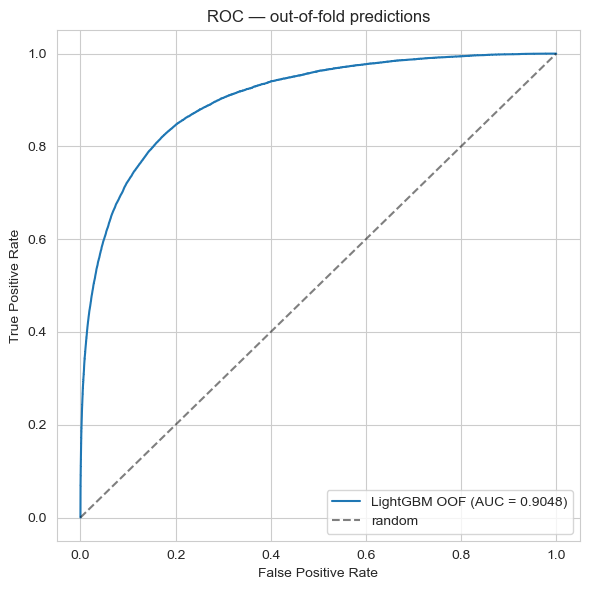

In [8]:
fpr, tpr, _ = roc_curve(y, oof)
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, label=f'LightGBM OOF (AUC = {oof_auc:.4f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC — out-of-fold predictions')
ax.legend()
plt.tight_layout()
plt.show()

## 6. Feature Importance (top 20 by mean gain)

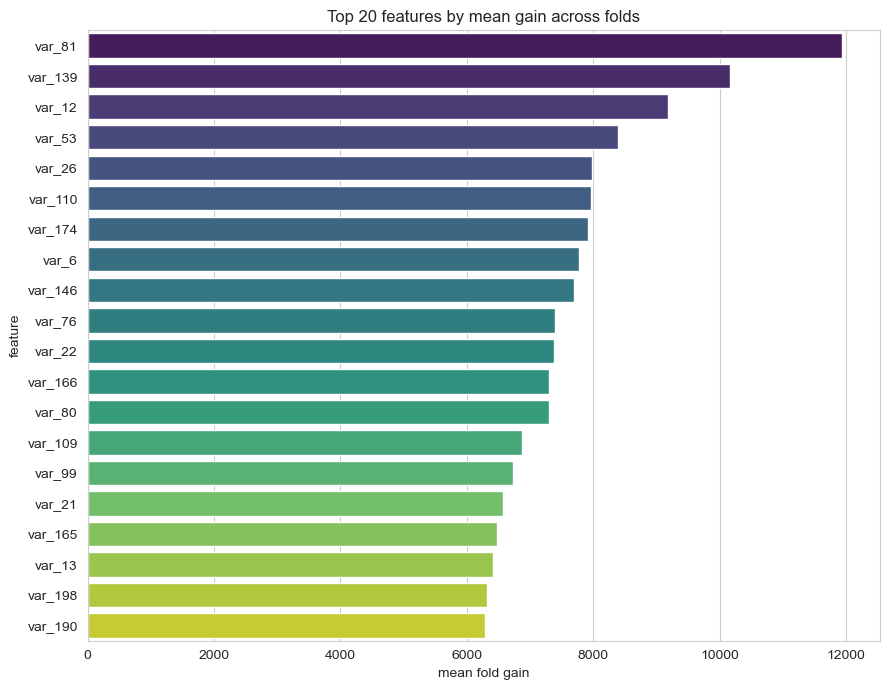

Top-20 feature breakdown:
  raw vars:    0
  VC counts:   0
  row stats:   0


In [9]:
imp_df = pd.DataFrame({'feature': all_feat_names,
                       'gain': importances / len(fold_models)}).sort_values('gain', ascending=False)
top20 = imp_df.head(20)

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=top20, x='gain', y='feature', palette='viridis', ax=ax)
ax.set_title('Top 20 features by mean gain across folds')
ax.set_xlabel('mean fold gain')
plt.tight_layout()
plt.show()

print('Top-20 feature breakdown:')
print(f'  raw vars:    {top20.feature.str.match(r"^var_\d+$").sum()}')
print(f'  VC counts:   {top20.feature.str.endswith("_vc").sum()}')
print(f'  row stats:   {top20.feature.str.startswith("row_").sum()}')

## 7. Fold-Averaged Test Prediction + Submission

In [10]:
test_proba = test_proba_folds.mean(axis=1)
print(f'Predicted {len(test_proba):,} test rows')
print(f'  mean prob: {test_proba.mean():.4f}  (target base rate: {y.mean():.4f})')
print(f'  std prob:  {test_proba.std():.4f}')
print(f'  range:     [{test_proba.min():.4f}, {test_proba.max():.4f}]')

submission = pd.DataFrame({'ID_code': test_ids, 'target': test_proba})
submission.to_csv('submission_lightgbm.csv', index=False)
print(f'\nWrote submission_lightgbm.csv  ({len(submission):,} rows)')
submission.head()

Predicted 200,000 test rows
  mean prob: 0.0806  (target base rate: 0.1005)
  std prob:  0.1390
  range:     [0.0001, 0.9978]

Wrote submission_lightgbm.csv  (200,000 rows)


,ID_code,target
0,test_0,0.084976
1,test_1,0.180289
2,test_2,0.202054
3,test_3,0.191008
4,test_4,0.043530


## 8. Save OOF for downstream notebooks

Persist OOF and per-fold test predictions so the experiments notebook can ensemble against them.

In [11]:
np.savez(f'{ART_DIR}/lgbm_baseline_predictions.npz',
         oof=oof, test_proba_folds=test_proba_folds, fold_aucs=fold_aucs)
print(f'Wrote {ART_DIR}/lgbm_baseline_predictions.npz')

Wrote artifacts/lgbm_baseline_predictions.npz
